In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from pathlib import Path
import json
from scipy.stats import ttest_ind
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv("ecommerce_clean_data.csv")


In [4]:

# Audit the existing profit calculation

expected_sales = (
    df["UnitPrice"]
    * df["Quantity"]
    * (1 - df["DiscountPct"] / 100)
)

expected_profit = (
    df["SalesAmount"]
    - df["CostPrice"] * df["Quantity"]
)

print(
    "Sales calculation matches:",
    np.allclose(df["SalesAmount"], expected_sales)
)

print(
    "Profit calculation matches:",
    np.allclose(df["Profit"], expected_profit)
)

print(
    "Maximum absolute profit difference:",
    (df["Profit"] - expected_profit).abs().max()
)


Sales calculation matches: True
Profit calculation matches: True
Maximum absolute profit difference: 3.637978807091713e-12


In [5]:
# Folter Delivered Orders
test_df = df[df["OrderStatus"] == "Delivered"].copy()

In [6]:
test_df["DiscountPct"].describe()

count    10970.000000
mean        10.737922
std          7.095532
min          0.000000
25%          5.000000
50%         10.000000
75%         15.000000
max         25.000000
Name: DiscountPct, dtype: float64

In [7]:
# Create two groups
order_level = (test_df.groupby("OrderID")
               .agg(
                   OrderValue=("SalesAmount","sum"),
                   DiscountPct=("DiscountPct","mean")
               )
                .reset_index())

In [8]:
order_level

,OrderID,OrderValue,DiscountPct
0,O00001,49930.00,10.000000
1,O00002,25521.25,7.500000
2,O00003,12541.90,5.000000
3,O00004,41731.20,15.000000
4,O00005,57555.85,15.000000
...,...,...,...
4381,O04995,19430.90,10.000000
4382,O04996,12673.50,7.500000
4383,O04998,24658.60,5.000000
4384,O04999,24078.25,10.000000


In [9]:
discount_group = order_level[order_level["DiscountPct"] > 0]["OrderValue"]

In [10]:
discount_group

0       49930.00
1       25521.25
2       12541.90
3       41731.20
4       57555.85
          ...   
4381    19430.90
4382    12673.50
4383    24658.60
4384    24078.25
4385    21834.00
Name: OrderValue, Length: 4230, dtype: float64

In [11]:
no_discount_group = order_level[order_level["DiscountPct"]==0]["OrderValue"]

In [12]:
print("Discount Orders :", len(discount_group))
print("No Discount Orders:",len(no_discount_group))

Discount Orders : 4230
No Discount Orders: 156


In [13]:
# Group Means

print(
    "Discount AOV :",
    discount_group.mean()
)
print("No discount AOV:",
      no_discount_group.mean())

Discount AOV : 35550.653794326245
No discount AOV: 18799.19230769231


In [14]:
# Group Median

print(
    "Discount AOV :",
    discount_group.median()
)
print("No discount AOV:",
      no_discount_group.median())

Discount AOV : 32649.199999999997
No discount AOV: 14292.0


In [15]:
# Visual Comparison
comparison_df =pd.DataFrame({
    "AOV": pd.concat(
        [discount_group , no_discount_group],
    ignore_index=True

    ),
    "Group": (
        ["Discount"] * len(discount_group)
        +["No Discount"] * len(no_discount_group)
    )
})

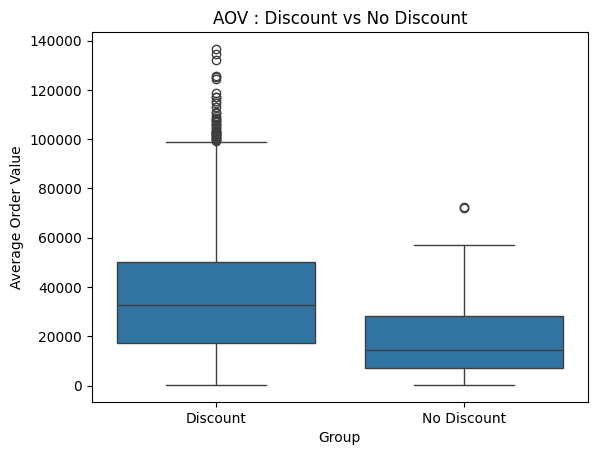

In [16]:
plt.Figure(figsize = (10,6))
sns.boxplot(
    data = comparison_df,
    x="Group",
    y="AOV"
)
plt.title("AOV : Discount vs No Discount")
plt.xlabel("Group")
plt.ylabel("Average Order Value")
plt.show()

In [17]:
# Independent t-test
t_stat,p_value = ttest_ind(
    discount_group,no_discount_group,equal_var=False
)

In [18]:
print("T-Statistic:",t_stat)
print("p_value:", p_value)

T-Statistic: 13.875792073637808
p_value: 1.8665022824881536e-30


In [19]:

alpha = 0.05

if p_value < alpha:
    print("Reject H0: The difference is statistically significant.")
else:
    print("Fail to reject H0: There is insufficient evidence of a difference.")

print(f"P-value: {p_value:.6f}")
print(f"Significance level: {alpha}")



Reject H0: The difference is statistically significant.
P-value: 0.000000
Significance level: 0.05


In [20]:
from scipy.stats import ttest_ind

result = ttest_ind(
    discount_group,no_discount_group,equal_var=False
)
print(result)

TtestResult(statistic=np.float64(13.875792073637808), pvalue=np.float64(1.8665022824881536e-30), df=np.float64(184.67236156483705))


In [21]:
result.confidence_interval()

ConfidenceInterval(low=np.float64(14369.699004998576), high=np.float64(19133.223968269296))

In [22]:
mean_diff =( discount_group.mean()
-
no_discount_group.mean())

In [23]:

Hypothesis_result = pd.DataFrame({
    "Metric": [
        "Discount AOV",
        "No Discount AOV",
        "Difference in AOV",
        "T-Statistic",
        "P-Value",
        "Alpha"
    ],
    "Value": [
        discount_group.mean(),
        no_discount_group.mean(),
        mean_diff,
        t_stat,
        p_value,
        alpha
    ]
})

Hypothesis_result


,Metric,Value
0,Discount AOV,3.555065e+04
1,No Discount AOV,1.879919e+04
2,Difference in AOV,1.675146e+04
3,T-Statistic,1.387579e+01
4,P-Value,1.866502e-30
5,Alpha,5.000000e-02


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12558 entries, 0 to 12557
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          12558 non-null  str    
 1   OrderDate        12558 non-null  str    
 2   CustomerID       12558 non-null  str    
 3   PaymentMethod    12558 non-null  str    
 4   OrderStatus      12558 non-null  str    
 5   CustomerName     12558 non-null  str    
 6   Gender           12558 non-null  str    
 7   Age              12558 non-null  int64  
 8   City             12558 non-null  str    
 9   Region           12558 non-null  str    
 10  SignupDate       12558 non-null  str    
 11  OrderDetailID    12558 non-null  str    
 12  ProductID        12558 non-null  str    
 13  Quantity         12558 non-null  int64  
 14  UnitPrice        12558 non-null  float64
 15  DiscountPct      12558 non-null  float64
 16  SalesAmount      12558 non-null  float64
 17  Profit           12558 

In [26]:
df.head()

,OrderID,OrderDate,CustomerID,PaymentMethod,OrderStatus,CustomerName,Gender,Age,City,Region,...,Profit,ProductName,Category,CostPrice,SellingPrice,Year,Month,Monthname,Year Name,profitmarginPct
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,12649.20,Mouse,Electronics,5353.0,10018.0,2026,1,January,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,6532.80,Shampoo,Beauty,3112.0,5568.0,2026,1,January,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3909.45,Table Lamp,Home,5905.0,10331.0,2026,2,February,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,2006.80,Air Fryer,Home,3425.0,4363.0,2026,2,February,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,4543.90,T-Shirt,Fashion,3999.0,6601.0,2025,11,November,2025-11,36.229758


In [27]:
target= "Profit"

In [28]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerID', 'PaymentMethod', 'OrderStatus',
       'CustomerName', 'Gender', 'Age', 'City', 'Region', 'SignupDate',
       'OrderDetailID', 'ProductID', 'Quantity', 'UnitPrice', 'DiscountPct',
       'SalesAmount', 'Profit', 'ProductName', 'Category', 'CostPrice',
       'SellingPrice', 'Year', 'Month', 'Monthname', 'Year Name',
       'profitmarginPct'],
      dtype='str')

In [29]:
Features = [
    "Quantity",
    "UnitPrice",
    "DiscountPct",
    "Category",
    "Region",
    "PaymentMethod"
]

In [30]:
x=df[Features]
y = df[target]

In [31]:
x.isnull().sum()

Quantity         0
UnitPrice        0
DiscountPct      0
Category         0
Region           0
PaymentMethod    0
dtype: int64

In [32]:
# train-test Split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=42)

In [33]:
Categorical_feature = [
    "Category",
    "Region",
    "PaymentMethod"
]

In [34]:
numeric_feature = [
    "Quantity",
    "UnitPrice",
    "DiscountPct"
]

In [35]:
# one hot encoding
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            Categorical_feature
        )
    ],
    remainder="passthrough"
)

In [36]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{fea

In [37]:
# model
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [38]:
# Pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",model)
    ]
)

In [39]:
pipeline.fit(
    x_train,y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains 

In [40]:
# prediction
y_pred = pipeline.predict(x_test)

In [41]:
# Actual vs Prediction
comparison = pd.DataFrame({
    "ActualProfit" : y_test.values,
    "PredictedProfit":y_pred
})
comparison.head(10)

,ActualProfit,PredictedProfit
0,3068.40,3056.53200
1,8642.00,9045.08300
2,502.35,496.76650
3,2876.35,2876.35000
4,1755.80,1751.57300
5,630.00,623.52150
6,-233.25,-172.29725
7,2379.80,2397.82000
8,2291.30,2303.24650
9,2184.00,2197.00000


In [42]:
#MAE
mae = mean_absolute_error(y_test,y_pred)
mae

73.4593164808931

In [43]:
# RMSE
rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)
rmse

np.float64(213.34551453319514)

In [44]:
#r2
r2 = r2_score(
    y_test,
    y_pred
)
r2

0.9979492010789576

In [45]:
print("MAE :",mae)
print("RMSE :",rmse)
print("R2 :",r2)

MAE : 73.4593164808931
RMSE : 213.34551453319514
R2 : 0.9979492010789576


Text(0.5, 1.0, 'Actual vs Prediction Profit')

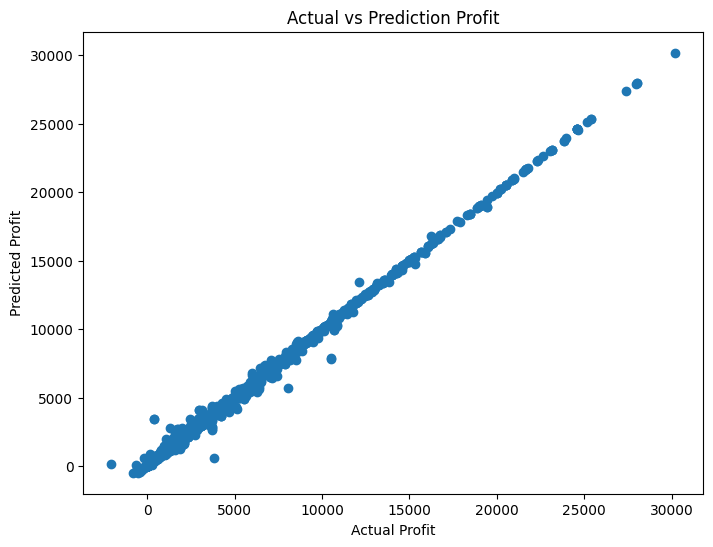

In [46]:
plt.figure(figsize=(8,6))

plt.scatter(y_test,y_pred)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Actual vs Prediction Profit")

In [47]:
residual = y_test - y_pred

In [48]:
residual.describe()

count    2512.000000
mean       -0.029081
std       213.387991
min     -3073.966000
25%       -14.669625
50%         0.000000
75%        13.703250
max      3256.270750
Name: Profit, dtype: float64

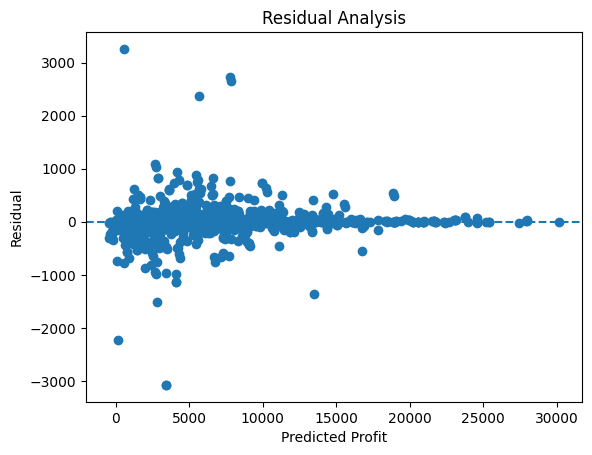

In [49]:
plt.Figure(figsize=(10,6))
plt.scatter(
    y_pred,
    residual
)
plt.axhline(
    0,linestyle="--"
)

plt.xlabel("Predicted Profit")
plt.ylabel("Residual")
plt.title("Residual Analysis")
plt.show()

In [50]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Split by OrderID so the same order cannot
# appear in both training and test data.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        x,
        y,
        groups=df.loc[x.index, "OrderID"]
    )
)

x_train = x.iloc[train_idx]
x_test = x.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Train the existing Random Forest pipeline
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)

# Baseline: predict the training-set mean profit
baseline = DummyRegressor(strategy="mean")
baseline.fit(x_train, y_train)
baseline_pred = baseline.predict(x_test)

# Compare both models on the same unseen orders
results = pd.DataFrame({
    "Model": ["Mean Baseline", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, y_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred))
    ],
    "R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, y_pred)
    ]
})

results.round(4)


,Model,MAE,RMSE,R2
0,Mean Baseline,3735.5163,5117.5106,-0.0016
1,Random Forest,63.5726,188.2505,0.9986


In [51]:

# Inspect the exact features used by the model

print("Model features:")
print(x.columns.tolist())

print("\nTarget variable:")
print(y.name)

print("\nPotential leakage columns in the dataset:")
for col in [
    "Profit",
    "SalesAmount",
    "CostPrice",
    "OrderID",
    "OrderStatus"
]:
    if col in x.columns:
        print(f"WARNING: {col} is included in model features")

print("\nTarget summary:")
print(y.describe())

print("\nFeature correlations with Profit (numeric features):")
numeric_features = x.select_dtypes(include="number")

print(
    numeric_features.corrwith(y)
    .sort_values(key=abs, ascending=False)
)


Model features:
['Quantity', 'UnitPrice', 'DiscountPct', 'Category', 'Region', 'PaymentMethod']

Target variable:
Profit

Potential leakage columns in the dataset:

Target summary:
count    12558.000000
mean      4804.382457
std       4894.725391
min      -2048.000000
25%       1342.400000
50%       3215.600000
75%       6608.400000
max      30860.000000
Name: Profit, dtype: float64

Feature correlations with Profit (numeric features):
UnitPrice      0.699047
Quantity       0.438354
DiscountPct   -0.235076
dtype: float64


In [52]:
# 1. Project paths
ROOT = Path.cwd()

In [53]:
# If the notebook is opened from a subfolder, use the project root.
if not (ROOT / "ecommerce_clean_data.csv").exists():
    ROOT = Path(r"C:\Users\Dell\Desktop\Ecommerce-Customer-Intelligence")

DATA_PATH = ROOT / "ecommerce_clean_data.csv"
ARTIFACTS = ROOT / "05_Streamlit_App" / "artifacts"

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

In [54]:
# 2. Load and check data
df = pd.read_csv(DATA_PATH)

features = [
    "Quantity", "UnitPrice", "DiscountPct",
    "Category", "Region", "PaymentMethod"
]
target = "Profit"

required = features + [target]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

df = df[required].copy()
df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target])

X = df[features]
y = df[target]

numeric_features = ["Quantity", "UnitPrice", "DiscountPct"]
categorical_features = ["Category", "Region", "PaymentMethod"]

print("Dataset shape:", df.shape)
print("Features:", features)
print("Target:", target)
print("\nTarget summary:")
print(y.describe())

Dataset shape: (12558, 7)
Features: ['Quantity', 'UnitPrice', 'DiscountPct', 'Category', 'Region', 'PaymentMethod']
Target: Profit

Target summary:
count    12558.000000
mean      4804.382457
std       4894.725391
min      -2048.000000
25%       1342.400000
50%       3215.600000
75%       6608.400000
max      30860.000000
Name: Profit, dtype: float64


In [55]:
# 3. Split BEFORE fitting preprocessing or models
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [56]:
# 4. Preprocessing inside the pipeline
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])

In [57]:
# 5. Baseline: predict the training-set mean
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

In [58]:
# 6. Random Forest
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different

In [59]:
pred = model.predict(X_test)

In [130]:
# 7. Evaluate on unseen test data
def evaluate(name, actual, predicted):
    return {
        "Model": name,
        "MAE": round(mean_absolute_error(actual, predicted), 4),
        "RMSE": round(
            np.sqrt(mean_squared_error(actual, predicted)), 4
        ),
        "R2": round(r2_score(actual, predicted), 4)
    }

results = pd.DataFrame([
    evaluate("Mean Baseline", y_test, baseline_pred),
    evaluate("Random Forest", y_test, pred)
])

print("\nMODEL COMPARISON")
print(results.to_string(index=False))


MODEL COMPARISON
        Model       MAE      RMSE      R2
Mean Baseline 3550.9898 4712.8597 -0.0007
Random Forest   98.6434  249.3514  0.9972


In [131]:
# 8. Save results for reproducibility
ARTIFACTS.mkdir(parents=True, exist_ok=True)
results.to_csv(ARTIFACTS / "model_metrics.csv", index=False)

In [132]:
# Save the model only if its predictions are valid
if not np.isfinite(pred).all():
    raise ValueError("Model generated invalid predictions.")

In [133]:
# IMPORTANT:
# Review the target formula and leakage risk before production use.
# This file is a validation-stage candidate, not proof that leakage
# has been ruled out.
joblib.dump(model, ARTIFACTS / "profit_prediction_pipeline.joblib")

with open(ARTIFACTS / "model_metadata.json", "w") as f:
    json.dump({
        "target": target,
        "features": features,
        "training_rows": len(X_train),
        "test_rows": len(X_test),
        "random_state": 42
    }, f, indent=2)

print("\nSaved model:", ARTIFACTS / "profit_prediction_pipeline.joblib")
print("Saved metrics:", ARTIFACTS / "model_metrics.csv")
print("Saved metadata:", ARTIFACTS / "model_metadata.json")



Saved model: c:\Users\Dell\Desktop\Ecommerce-Customer-Intelligence\05_Streamlit_App\artifacts\profit_prediction_pipeline.joblib
Saved metrics: c:\Users\Dell\Desktop\Ecommerce-Customer-Intelligence\05_Streamlit_App\artifacts\model_metrics.csv
Saved metadata: c:\Users\Dell\Desktop\Ecommerce-Customer-Intelligence\05_Streamlit_App\artifacts\model_metadata.json
